# 6. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the structure, distribution, and characteristics of the integrated dataset before conducting statistical analysis.

This section examines the three main analytical variables:
- Physical inactivity prevalence (%)
- Obesity prevalence (%)
- GDP per capita (current euros)

Descriptive statistics and visualisations will be used to identify patterns, variability, and potential outliers.

## 6.1 Load the Analytical Dataset

The integrated dataset generated during the data preparation stage is loaded from the processed data directory.

The dataset is inspected to confirm that it is available and retains the expected structure.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests

analysis_df = pd.read_csv("../data/processed/analysis_dataset.csv")

print("Dataset shape:", analysis_df.shape)
display(analysis_df.head())

Dataset shape: (35, 4)


,geo,physical_inactivity_pct,obesity_pct,gdp_per_capita
0,AL,24.279688,12.6,7360
1,AT,19.757990,17.7,49640
2,BA,21.074688,15.7,6790
3,BE,25.410315,15.8,48090
4,BG,32.280933,11.7,13350


## 6.2 Initial Dataset Inspection

Before examining individual variable distributions, the dataset is inspected to understand its structure, data types, and descriptive statistics.

This provides an initial overview of the analytical variables and helps identify any potential data quality issues.

In [2]:
analysis_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   geo                      35 non-null     str    
 1   physical_inactivity_pct  35 non-null     float64
 2   obesity_pct              35 non-null     float64
 3   gdp_per_capita           35 non-null     int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 1.2 KB


In [3]:
analysis_df.describe()

,physical_inactivity_pct,obesity_pct,gdp_per_capita
count,35.000000,35.000000,35.000000
mean,26.228928,16.557143,37046.000000
std,11.016000,4.413168,29972.304098
min,8.695465,7.100000,6790.000000
25%,19.396056,13.500000,17530.000000
50%,23.366205,16.700000,26980.000000
75%,35.155559,19.400000,48865.000000
max,51.653690,26.100000,117100.000000


### 6.2.1 Interpretation of Descriptive Statistics

The descriptive statistics provide an initial overview of the three analytical variables across the 35 countries.

Physical inactivity: The average prevalence is 26.23%, with a median of 23.37%. The standard deviation of 11.02 percentage points indicates considerable variation between countries. The mean being higher than the median suggests a potential right-skewed distribution.

Obesity prevalence: The average is 16.56%, while the median is 16.70%. These similar values suggest a relatively balanced distribution. The standard deviation of 4.41 percentage points indicates less variation than observed for physical inactivity.

GDP per capita: The average GDP per capita is €37,046, compared with a median of €26,980. The substantial difference between these values suggests a right-skewed distribution, potentially influenced by countries with particularly high GDP per capita.

These observations provide an initial understanding of the data. The distributions will be examined visually in the following section to assess their shape and identify potential outliers.

## 6.3 Visualising Variable Distributions

Histograms are used to examine the distribution of each analytical variable.

They help identify:
- The concentration of observations.
- The shape and symmetry of distributions.
- Potential skewness.
- Possible unusually high or low observations.

The distributions are examined individually before investigating relationships between variables.

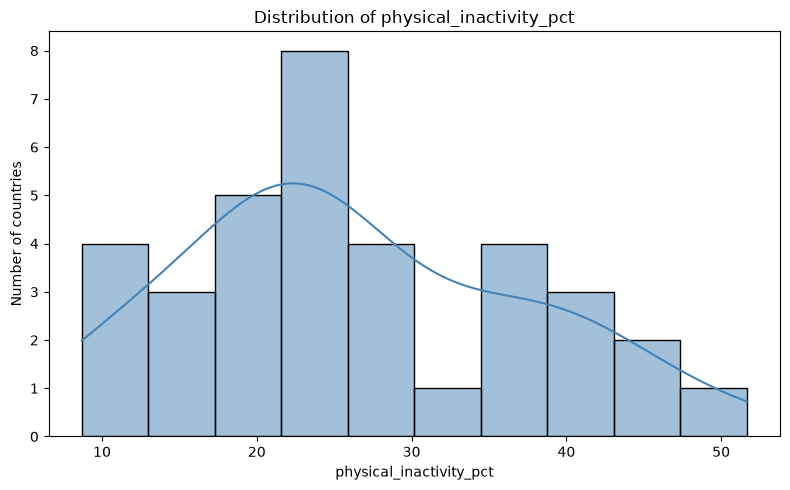

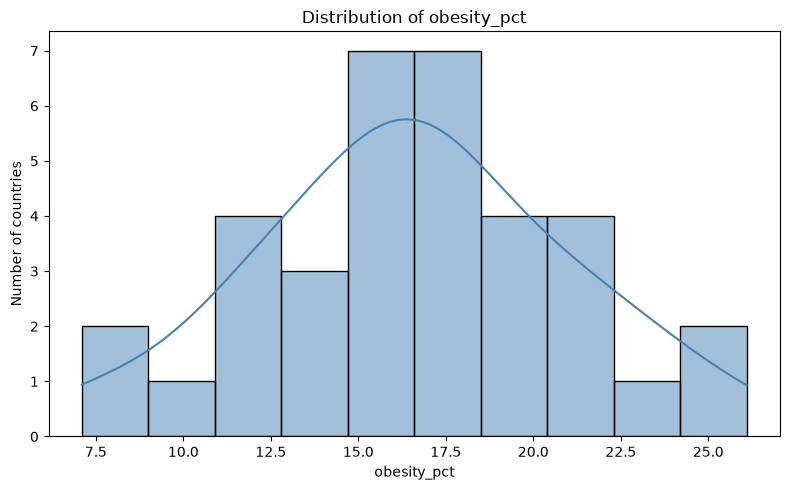

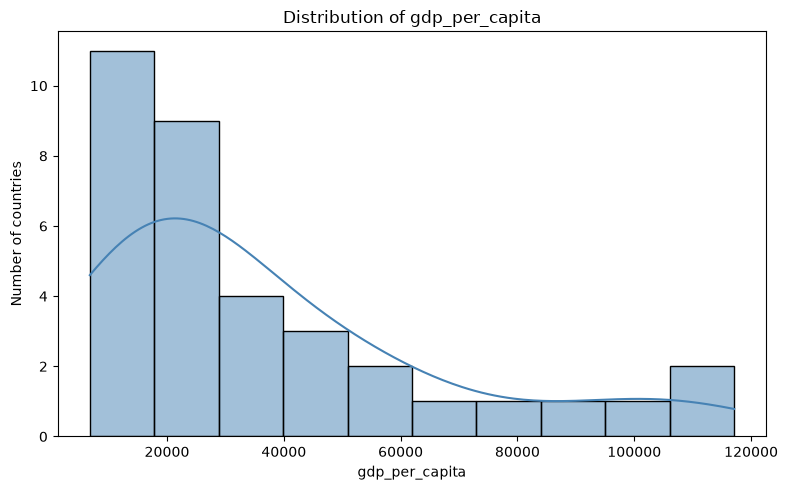

In [4]:
# Define the analytical variables
variables = [
    "physical_inactivity_pct",
    "obesity_pct",
    "gdp_per_capita"
]

# Plot the distribution of each variable
for variable in variables:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=analysis_df,
        x=variable,
        bins=10,
        kde=True,
        color="steelblue"
    )

    plt.title(f"Distribution of {variable}")
    plt.xlabel(variable)
    plt.ylabel("Number of countries")
    plt.tight_layout()
    plt.show()

### 6.3.1 Interpretation of Variable Distributions

The histograms provide further insight into the distribution of the three analytical variables.

**Physical inactivity:** The distribution shows a concentration of countries around the 20–25% range, with a longer tail towards higher values. This suggests moderate positive skewness and considerable variation in physical inactivity prevalence across countries.

**Obesity prevalence:** The distribution appears relatively symmetric, with most observations concentrated around 15–18%. This is consistent with the similar mean and median values observed in the descriptive statistics.

**GDP per capita:** The distribution is strongly right-skewed. Most countries have GDP per capita values in the lower ranges, while a smaller number of countries have substantially higher values. This explains the considerable difference between the mean and median.

Overall, the visualisations reveal differences in the distributions of the three variables. In particular, GDP per capita shows substantial positive skewness, while obesity prevalence appears more symmetrically distributed.

### 6.4 Visualising Potential Outliers

Boxplots are used to examine the spread of each analytical variable and identify potential outliers.

A boxplot displays:
- The median (50th percentile).
- The first and third quartiles (25th and 75th percentiles).
- The interquartile range (IQR).
- Whiskers representing the range of non-outlier observations.
- Individual points beyond the whiskers, which are potential outliers.

The visualisation helps identify observations that may require further investigation.

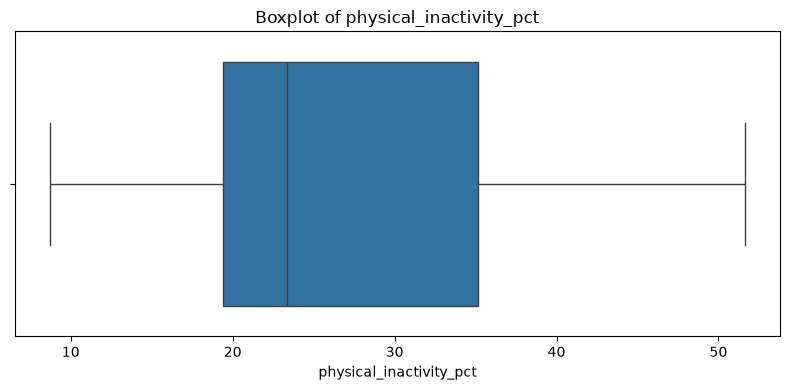

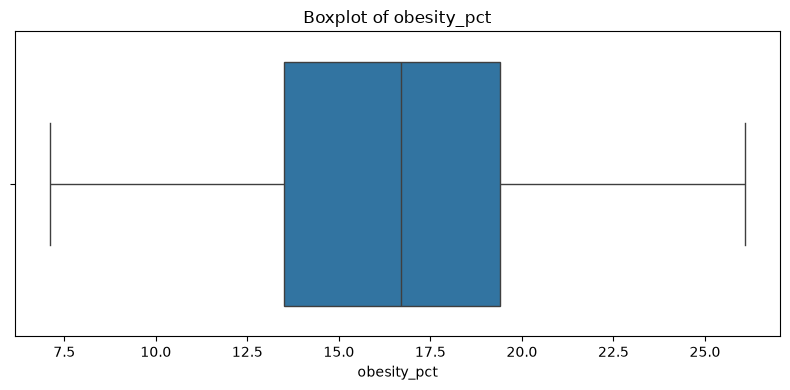

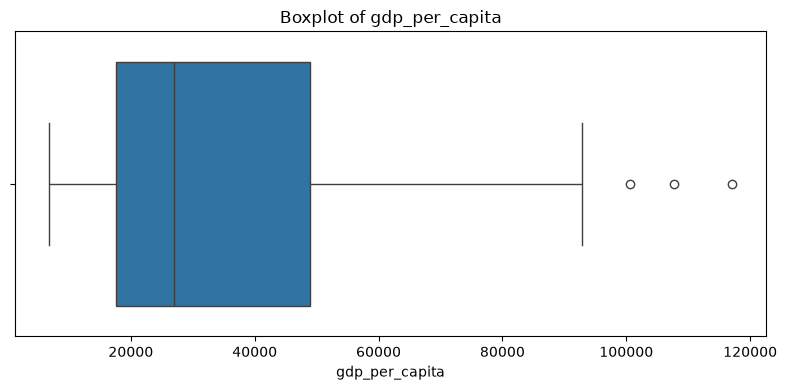

In [5]:
# Create boxplots for the three analytical variables

for variable in variables:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=analysis_df,
        x=variable
    )

    plt.title(f"Boxplot of {variable}")
    plt.xlabel(variable)
    plt.tight_layout()
    plt.show()

In [6]:
# Identify potential outliers using the IQR method

for variable in variables:
    Q1 = analysis_df[variable].quantile(0.25)
    Q3 = analysis_df[variable].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = analysis_df[
        (analysis_df[variable] < lower_bound) |
        (analysis_df[variable] > upper_bound)
    ]

    print(f"\n{variable}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower boundary: {lower_bound:.2f}")
    print(f"Upper boundary: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")

    display(outliers[["geo", variable]])


physical_inactivity_pct
IQR: 15.76
Lower boundary: -4.24
Upper boundary: 58.79
Potential outliers: 0


,geo,physical_inactivity_pct



obesity_pct
IQR: 5.90
Lower boundary: 4.65
Upper boundary: 28.25
Potential outliers: 0


,geo,obesity_pct



gdp_per_capita
IQR: 31335.00
Lower boundary: -29472.50
Upper boundary: 95867.50
Potential outliers: 3


,geo,gdp_per_capita
16,IE,100630
20,LU,117100
26,NO,107660


#### 6.4.1 Interpretation of Potential Outliers

The IQR method identified different patterns across the three analytical variables.

**Physical inactivity:** No potential outliers were identified. All 35 countries fall within the calculated lower and upper boundaries. Despite this, the variable shows considerable variation across countries.

**Obesity prevalence:** No potential outliers were identified. The observations are relatively concentrated within the calculated boundaries.

**GDP per capita:** Three potential outliers were identified: Ireland (€100,630), Luxembourg (€117,100), and Norway (€107,660). All three exceed the upper boundary of €95,867.50, indicating unusually high GDP per capita values compared with the rest of the analytical sample.

The results are consistent with the previously observed right-skewed GDP distribution.

The identified GDP observations are retained because they represent valid country-level economic values. Statistical outliers are not necessarily errors and should not be removed without further investigation.

Overall, the IQR analysis indicates that GDP per capita has a more pronounced concentration of extreme values than physical inactivity and obesity prevalence.

### 6.5 Exploring Relationships Between Variables

After examining the individual distributions, the analysis moves to exploring relationships between physical inactivity, obesity prevalence, and GDP per capita.

Correlation analysis and scatterplots are used to investigate the direction and strength of potential associations between the variables.

These techniques provide an initial understanding of the relationships before conducting formal statistical analysis.

#### 6.5.1 Correlation Heatmap

A correlation matrix is calculated to examine the pairwise linear relationships between the numerical variables.

Pearson's correlation coefficient is used as an initial measure of linear association. The results are visualised using a heatmap.

In [7]:
# Calculate the Pearson correlation matrix

correlation_matrix = analysis_df[
    [
        "physical_inactivity_pct",
        "obesity_pct",
        "gdp_per_capita"
    ]
].corr(method="pearson")

# Display the correlation matrix
display(correlation_matrix)

,physical_inactivity_pct,obesity_pct,gdp_per_capita
physical_inactivity_pct,1.000000,-0.217542,-0.335485
obesity_pct,-0.217542,1.000000,0.174467
gdp_per_capita,-0.335485,0.174467,1.000000


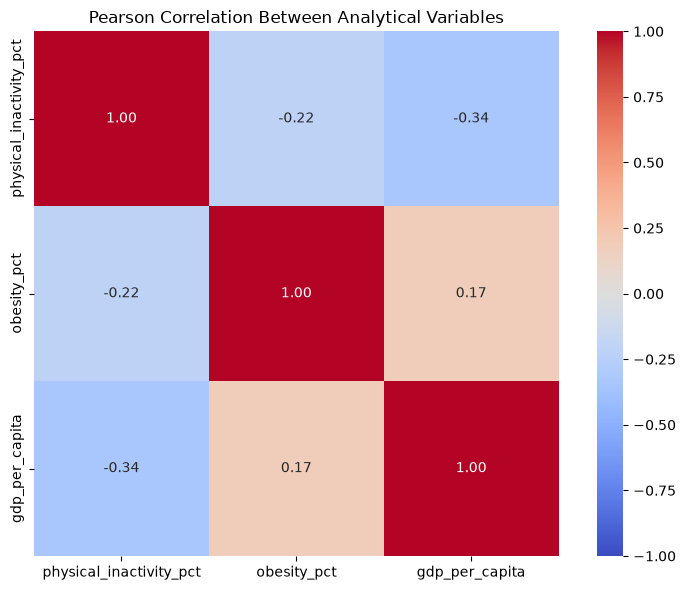

In [8]:
# Create a correlation heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Pearson Correlation Between Analytical Variables")
plt.tight_layout()
plt.show()

#### 6.5.2 Pairwise Scatterplots

Scatterplots are created to visually examine the relationships between the three analytical variables.

Each point represents one country. The plots help identify potential linear or non-linear patterns, unusual observations, and differences in the distribution of countries.

The visualisations complement the correlation matrix by showing the underlying observations rather than only a numerical summary.

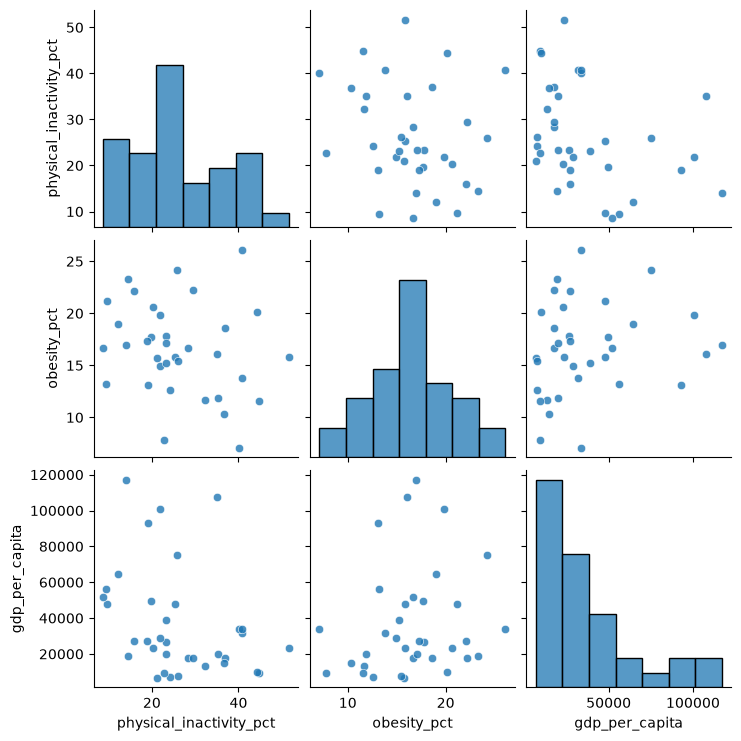

In [9]:
# Create pairwise scatterplots for the analytical variables

sns.pairplot(
    analysis_df[
        [
            "physical_inactivity_pct",
            "obesity_pct",
            "gdp_per_capita"
        ]
    ],
    diag_kind="hist",
    plot_kws={"alpha": 0.8}
)

plt.show()

#### 6.5.3 Interpretation of Correlation Analysis

The Pearson correlation matrix reveals relatively weak linear associations between the three analytical variables.

**Physical inactivity and obesity:** A weak negative correlation was observed (r = -0.22). This indicates a slight negative linear association between physical inactivity and obesity prevalence across the 35 countries. The scatterplot also shows considerable dispersion, without a clear linear pattern.

**Physical inactivity and GDP per capita:** A weak negative correlation was observed (r = -0.34). This suggests that countries with higher GDP per capita tend to have somewhat lower physical inactivity prevalence. However, the relationship is not particularly strong.

**Obesity and GDP per capita:** A very weak positive correlation was observed (r = 0.17). The scatterplot does not reveal a clear linear relationship between these variables.

Overall, the correlation analysis does not reveal strong linear associations between any of the three variables. The scatterplots support these observations by showing considerable variation between countries.

These results represent exploratory findings and do not establish causal relationships. Further statistical analysis is required to assess the strength and statistical significance of the observed associations.

### 6.6 Comparing Pearson and Spearman Correlations

Pearson correlation measures the strength and direction of linear relationships between variables. However, it can be sensitive to extreme observations and may not adequately describe non-linear relationships.

To complement the Pearson analysis, Spearman rank correlation is calculated.

Spearman correlation evaluates monotonic relationships using the ranks of observations rather than their original values. It is generally less sensitive to extreme values and can identify monotonic associations that are not necessarily linear.

Comparing both methods provides a broader understanding of the relationships between the analytical variables.

#### 6.6.1 Calculate Spearman Correlations

In [10]:
# Calculate Spearman correlation matrix

spearman_matrix = analysis_df[
    [
        "physical_inactivity_pct",
        "obesity_pct",
        "gdp_per_capita"
    ]
].corr(method="spearman")

display(spearman_matrix)

,physical_inactivity_pct,obesity_pct,gdp_per_capita
physical_inactivity_pct,1.000000,-0.248074,-0.409973
obesity_pct,-0.248074,1.000000,0.260699
gdp_per_capita,-0.409973,0.260699,1.000000


#### 6.6.2 Compare Pearson and Spearman Results

In [11]:
# Compare Pearson and Spearman correlation coefficients

correlation_comparison = pd.DataFrame({
    "Pearson": correlation_matrix.unstack(),
    "Spearman": spearman_matrix.unstack()
})

display(correlation_comparison)

Pearson  Spearman
physical_inactivity_pct physical_inactivity_pct  1.000000  1.000000
                        obesity_pct             -0.217542 -0.248074
                        gdp_per_capita          -0.335485 -0.409973
obesity_pct             physical_inactivity_pct -0.217542 -0.248074
                        obesity_pct              1.000000  1.000000
                        gdp_per_capita           0.174467  0.260699
gdp_per_capita          physical_inactivity_pct -0.335485 -0.409973
                        obesity_pct              0.174467  0.260699
                        gdp_per_capita           1.000000  1.000000

#### 6.6.3 Visualise the Spearman Correlation Matrix

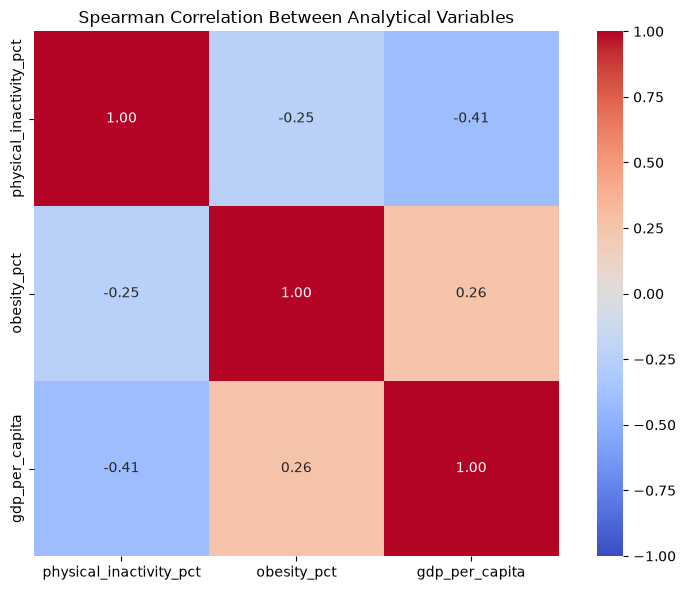

In [12]:
# Visualise Spearman correlations

plt.figure(figsize=(8, 6))

sns.heatmap(
    spearman_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Spearman Correlation Between Analytical Variables")
plt.tight_layout()
plt.show()

#### 6.6.4 Interpretation of Pearson and Spearman Correlations

The comparison between Pearson and Spearman correlation coefficients reveals similar directions of association across all three variable pairs. However, Spearman coefficients show slightly stronger associations in absolute terms.

**Physical inactivity and obesity:** Pearson correlation (-0.218) and Spearman correlation (-0.248) both indicate a weak negative association. The similarity between the coefficients suggests that the observed relationship remains relatively consistent across both methods.

**Physical inactivity and GDP per capita:** Pearson correlation (-0.335) and Spearman correlation (-0.410) indicate a negative association. The stronger Spearman coefficient suggests that the monotonic relationship between the variables is somewhat more pronounced than their linear relationship.

**Obesity and GDP per capita:** Pearson correlation (0.174) and Spearman correlation (0.261) both indicate a weak positive association, with Spearman showing a somewhat stronger relationship.

Overall, the two methods produce consistent directions of association, although their magnitudes differ. The differences suggest that the relationships may not be fully represented by linear correlation alone.

Since GDP per capita has a right-skewed distribution and several potential outliers, Spearman correlation provides a useful complementary perspective. Neither method establishes causation or, by itself, determines whether an observed association is statistically significant.

# 7. Statistical Analysis and Hypothesis Testing

## 7.1 Formulating the Hypotheses

Research Question 1

Is physical inactivity associated with obesity prevalence?
- H₀: There is no association between physical inactivity and obesity prevalence.
- H₁: There is an association between physical inactivity and obesity prevalence.

Research Question 2

Is GDP per capita associated with physical inactivity?
- H₀: There is no association between GDP per capita and physical inactivity.
- H₁: There is an association between GDP per capita and physical inactivity.

Research Question 3

Is GDP per capita associated with obesity prevalence?
- H₀: There is no association between GDP per capita and obesity prevalence.
- H₁: There is an association between GDP per capita and obesity prevalence.

## 7.2 Performing the Statistical Tests

In [13]:
# Define the variable pairs corresponding to our research questions

research_pairs = {
    "Physical inactivity vs. obesity": (
        "physical_inactivity_pct",
        "obesity_pct"
    ),
    "GDP vs. physical inactivity": (
        "gdp_per_capita",
        "physical_inactivity_pct"
    ),
    "GDP vs. obesity": (
        "gdp_per_capita",
        "obesity_pct"
    )
}

# Set the significance level
alpha = 0.05

# Perform Pearson and Spearman correlation tests

for question, (var1, var2) in research_pairs.items():

    pearson_result = pearsonr(
        analysis_df[var1],
        analysis_df[var2]
    )

    spearman_result = spearmanr(
        analysis_df[var1],
        analysis_df[var2]
    )

    print(f"\n{question}")
    print("-" * 50)

    print(
        f"Pearson: r = {pearson_result.statistic:.3f}, "
        f"p-value = {pearson_result.pvalue:.4f}"
    )

    print(
        f"Spearman: rho = {spearman_result.statistic:.3f}, "
        f"p-value = {spearman_result.pvalue:.4f}"
    )


Physical inactivity vs. obesity
--------------------------------------------------
Pearson: r = -0.218, p-value = 0.2093
Spearman: rho = -0.248, p-value = 0.1507

GDP vs. physical inactivity
--------------------------------------------------
Pearson: r = -0.335, p-value = 0.0488
Spearman: rho = -0.410, p-value = 0.0144

GDP vs. obesity
--------------------------------------------------
Pearson: r = 0.174, p-value = 0.3162
Spearman: rho = 0.261, p-value = 0.1304


### 7.2.1 Interpretation of Statistical Test Results

The correlation hypothesis tests produced different results across the three research questions.

**Physical inactivity and obesity:** Both Pearson (r = -0.218, p = 0.2093) and Spearman (ρ = -0.248, p = 0.1507) indicate weak negative associations. However, neither result is statistically significant at the 5% level. Therefore, the null hypothesis cannot be rejected.

**GDP per capita and physical inactivity:** Both Pearson (r = -0.335, p = 0.0488) and Spearman (ρ = -0.410, p = 0.0144) indicate negative associations. Both tests are statistically significant at the unadjusted 5% level. This suggests that countries with higher GDP per capita tend to have lower physical inactivity prevalence in the analytical sample.

**GDP per capita and obesity:** Pearson (r = 0.174, p = 0.3162) and Spearman (ρ = 0.261, p = 0.1304) indicate weak positive associations. Neither result is statistically significant at the 5% level, so the null hypothesis cannot be rejected.

Overall, the strongest evidence of an association was observed between GDP per capita and physical inactivity. The other two relationships did not demonstrate statistically significant associations in this sample.

These findings should be interpreted cautiously due to the relatively small sample of 35 countries, the observational nature of the data, and the use of multiple statistical tests. Statistical significance does not establish causation.

## 7.3 Confidence intervals

In [14]:
gdp_inactivity_result = pearsonr(
    analysis_df["gdp_per_capita"],
    analysis_df["physical_inactivity_pct"]
)

gdp_inactivity_ci = gdp_inactivity_result.confidence_interval(
    confidence_level=0.95
)

print("Pearson correlation:", gdp_inactivity_result.statistic)
print("95% confidence interval:", gdp_inactivity_ci)

Pearson correlation: -0.3354853876977855
95% confidence interval: ConfidenceInterval(low=np.float64(-0.6014861715319053), high=np.float64(-0.0025206501797236398))


### 7.3.1 Interpretation of the Confidence Interval

The 95% confidence interval for the Pearson correlation between GDP per capita and physical inactivity ranges from -0.6015 to -0.0025.

Since the interval does not include zero, the results suggest a statistically significant negative linear association at the 5% significance level.

However, the relatively wide interval indicates uncertainty about the actual strength of this association. The results should also be interpreted cautiously because the analytical dataset contains a selected group of 35 countries rather than a random sample of all European countries.

## 7.4 Multiple testing

In [15]:
spearman_p_values = []

for var1, var2 in research_pairs.values():
    spearman_result = spearmanr(
        analysis_df[var1],
        analysis_df[var2]
    )

    spearman_p_values.append(spearman_result.pvalue)

holm_results = multipletests(
    spearman_p_values,
    alpha=0.05,
    method="holm"
)

print("Original p-values:", spearman_p_values)
print("Adjusted p-values:", holm_results[1])
print("Significant results:", holm_results[0])

Original p-values: [np.float64(0.1507470586909262), np.float64(0.014447355113229372), np.float64(0.1303819460762632)]
Adjusted p-values: [0.26076389 0.04334207 0.26076389]
Significant results: [False  True False]


### 7.4.1 Interpretation of Holm's Correction

The Holm correction was applied to the three Spearman correlation tests to account for multiple comparisons and reduce the risk of false-positive findings.

After the correction, the association between GDP per capita and physical inactivity remains statistically significant (adjusted p-value ≈ 0.0433), which is below the significance threshold of 0.05.

The associations between physical inactivity and obesity prevalence, and between GDP per capita and obesity prevalence, are not statistically significant after the correction.

Therefore, only the relationship between GDP per capita and physical inactivity provides sufficient statistical evidence of an association in this sample.

## 7.5 Summary of correlation and hypothesis testing results

In [16]:
results_rows = []

for question, (var1, var2) in research_pairs.items():
    pearson_result = pearsonr(analysis_df[var1], analysis_df[var2])
    spearman_result = spearmanr(analysis_df[var1], analysis_df[var2])

    results_rows.append({
        "Research question": question,
        "Pearson r": pearson_result.statistic,
        "Spearman rho": spearman_result.statistic,
        "Spearman p-value": spearman_result.pvalue
    })

results_df = pd.DataFrame(results_rows)

results_df["Spearman adjusted p-value"] = multipletests(
    results_df["Spearman p-value"],
    alpha=0.05,
    method="holm"
)[1]

results_df["Significant after Holm"] = (
    results_df["Spearman adjusted p-value"] < 0.05
)

display(results_df.round(4))

,Research question,Pearson r,Spearman rho,Spearman p-value,Spearman adjusted p-value,Significant after Holm
0,Physical inactivity vs. obesity,-0.2175,-0.2481,0.1507,0.2608,False
1,GDP vs. physical inactivity,-0.3355,-0.4100,0.0144,0.0433,True
2,GDP vs. obesity,0.1745,0.2607,0.1304,0.2608,False


### 7.5.2 Overall Findings

The statistical analysis identified one statistically significant association among the three research questions.

GDP per capita showed a moderate negative monotonic association with physical inactivity (Spearman's ρ = -0.4100, adjusted p-value = 0.0433). This relationship remained statistically significant after applying Holm's correction for multiple testing.

No statistically significant associations were identified between physical inactivity and obesity prevalence or between GDP per capita and obesity prevalence.

The Pearson and Spearman correlation coefficients generally showed consistent directions, although their magnitudes differed slightly. This supports using Spearman correlation as the primary method while treating Pearson correlation as a complementary analysis.

These findings describe associations observed across 35 European countries in 2022. They do not establish causal relationships. The relatively small analytical sample, country-level aggregation, and use of GDP per capita at current prices should be considered when interpreting the results.

## 7.6 Visualising Relationships

Scatterplots are used to visualise the relationships between the three
analytical variables.

Each point represents one country. Trend lines help illustrate the
overall direction of the relationships and complement the correlation
analysis.

### Physical Inactivity vs. Obesity Prevalence (2022)

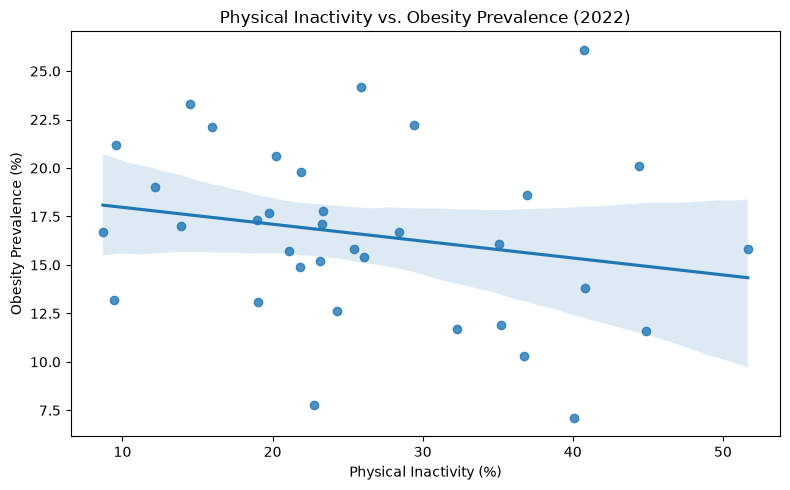

In [17]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=analysis_df,
    x="physical_inactivity_pct",
    y="obesity_pct"
)

plt.title("Physical Inactivity vs. Obesity Prevalence (2022)")
plt.xlabel("Physical Inactivity (%)")
plt.ylabel("Obesity Prevalence (%)")

plt.tight_layout()
plt.show()

**Interpretation**

The scatterplot shows a slight downward trend, indicating a weak negative relationship between physical inactivity and obesity prevalence across the analysed countries.

However, the data points are widely scattered around the regression line, suggesting that the relationship is weak. This visual observation is consistent with the Pearson and Spearman correlation results.

The association was not statistically significant after Holm's correction (adjusted p-value = 0.2608). Therefore, the analysis does not provide sufficient statistical evidence of an association between these two variables.

### GDP per Capita vs. Physical Inactivity (2022)

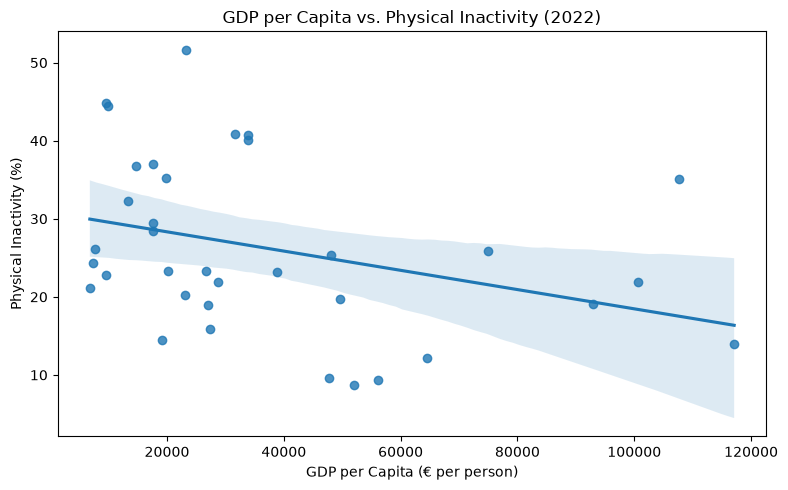

In [18]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=analysis_df,
    x="gdp_per_capita",
    y="physical_inactivity_pct"
)

plt.title("GDP per Capita vs. Physical Inactivity (2022)")
plt.xlabel("GDP per Capita (€ per person)")
plt.ylabel("Physical Inactivity (%)")

plt.tight_layout()
plt.show()

**Interpretation**

The scatterplot shows a downward trend, suggesting a negative relationship between GDP per capita and physical inactivity across the analysed countries.

The data points are relatively widely dispersed around the regression line, indicating that GDP per capita alone does not explain the differences in physical inactivity between countries.

The visual pattern is consistent with the correlation analysis. Both Pearson and Spearman coefficients indicate a negative association, with Spearman showing a moderate negative monotonic relationship (ρ = -0.4100).

This relationship remained statistically significant after Holm's correction (adjusted p-value = 0.0433).

The confidence band around the regression line represents uncertainty in the estimated average trend, not a range expected to contain individual country observations.

### GDP per Capita vs. Obesity Prevalence (2022)

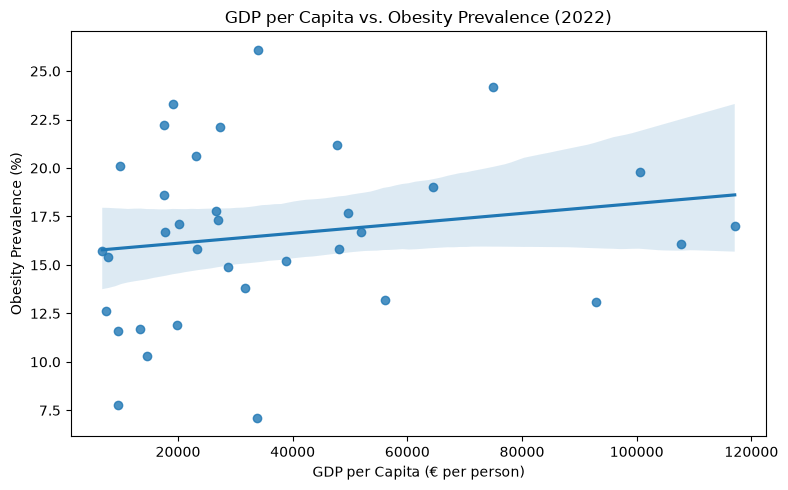

In [19]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=analysis_df,
    x="gdp_per_capita",
    y="obesity_pct"
)

plt.title("GDP per Capita vs. Obesity Prevalence (2022)")
plt.xlabel("GDP per Capita (€ per person)")
plt.ylabel("Obesity Prevalence (%)")

plt.tight_layout()
plt.show()

**Interpretation**

The scatterplot shows a slight upward trend, suggesting a weak positive relationship between GDP per capita and obesity prevalence across the analysed countries.

However, the data points are widely dispersed around the regression line, indicating that the relationship is weak.

This observation is consistent with the correlation analysis. Both Pearson and Spearman coefficients indicate a positive association, but neither provides statistically significant evidence after Holm's correction (adjusted p-value = 0.2608).

Therefore, the analysis does not provide sufficient statistical evidence of an association between GDP per capita and obesity prevalence in the selected sample.

# 8. Conclusions and Limitations

## 8.1 Conclusions

This project examined the relationships between physical inactivity, obesity prevalence, and GDP per capita across 35 countries in the WHO European Region for 2022.

Three research questions were investigated using descriptive statistics, Pearson and Spearman correlation analysis, hypothesis testing, and visualisations.

### Research Question 1: Is physical inactivity associated with obesity prevalence?

The analysis identified a weak negative correlation between physical inactivity and obesity prevalence (Spearman's ρ = -0.2481).

However, this relationship was not statistically significant after Holm's correction (adjusted p-value = 0.2608).

Therefore, the analysis did not provide sufficient statistical evidence of an association between these variables in the selected sample.

### Research Question 2: Is GDP per capita associated with physical inactivity?

The analysis identified a moderate negative monotonic association between GDP per capita and physical inactivity (Spearman's ρ = -0.4100).

This relationship remained statistically significant after Holm's correction (adjusted p-value = 0.0433).

The results suggest that countries with higher GDP per capita tended to have lower physical inactivity prevalence in 2022.

This was the only relationship among the three research questions that remained statistically significant after multiple-testing correction.

### Research Question 3: Is GDP per capita associated with obesity prevalence?

The analysis identified a weak positive correlation between GDP per capita and obesity prevalence (Spearman's ρ = 0.2607).

However, this relationship was not statistically significant after Holm's correction (adjusted p-value = 0.2608).

Therefore, the analysis did not provide sufficient statistical evidence of an association between these variables in the selected sample.

### Overall Conclusion

Among the three investigated relationships, only GDP per capita and physical inactivity showed statistically significant evidence of an association after correcting for multiple testing.

The findings highlight a potential relationship between economic indicators and physical activity patterns across countries. However, the analysis does not establish causation, and the observed relationships should be interpreted within the limitations of the available data and analytical sample.

## 8.2 Limitations

Several limitations should be considered when interpreting the findings of this project.

### 1. Limited Analytical Sample

The final analytical dataset contains 35 countries with complete observations across all three data sources. The sample was determined by data availability rather than random sampling. Consequently, the findings may not be representative of all countries in the WHO European Region.

### 2. Correlation Does Not Imply Causation

The analysis identifies statistical associations but does not establish causal relationships. Other factors, such as education, urban planning, healthcare systems, and employment patterns, may influence physical inactivity and obesity prevalence.

### 3. Ecological Fallacy

The analysis uses aggregated country-level data. Relationships observed between countries cannot automatically be applied to individuals within those countries. For example, a relationship between national GDP per capita and physical inactivity does not demonstrate that individuals with higher incomes are more physically active.

### 4. Cross-Sectional Data

The analysis focuses exclusively on 2022. As a result, it provides a snapshot of relationships at one point in time and cannot identify trends, changes, or potential time-lagged relationships between the variables.

### 5. Measurement and Comparability Limitations

The analytical variables originate from different statistical sources and may involve different measurement methodologies and estimation procedures. Furthermore, GDP per capita is expressed in current euros and is not adjusted for purchasing power differences between countries. It should therefore not be interpreted as a direct measure of individual income or comparable living standards.

These limitations should be considered when interpreting the statistical results and drawing conclusions from the analysis.

## 8.3 Future Work

Several extensions could improve and expand the current analysis.

### 1. Longitudinal Analysis

Future research could include multiple years of data to investigate trends and changes in physical inactivity, obesity prevalence, and GDP per capita over time. This would provide a broader perspective than the single-year analysis conducted in this project.

### 2. Additional Explanatory Variables

Including additional socioeconomic and environmental indicators, such as education levels, unemployment rates, urbanisation, healthcare expenditure, and access to recreational facilities, could help investigate other factors associated with physical inactivity and obesity.

### 3. Purchasing Power-Adjusted GDP

Replacing GDP per capita at current prices with GDP per capita adjusted for Purchasing Power Standards (PPS) could improve cross-country economic comparisons by accounting for differences in price levels.

### 4. Individual-Level Analysis

Using individual-level survey data could help investigate relationships between personal income, education, physical activity, and obesity. This would provide a way to examine relationships at the individual level rather than relying exclusively on country-level aggregates.

These extensions could provide a more comprehensive understanding of the socioeconomic and health-related factors associated with physical activity and obesity across Europe.